# 02b - Membuat model yang robust terhadap data tidak lengkap
Lanjutan dari `02_model_selection.ipynb`.

## Latar belakang
Pada notebook 02, model bagus pada data bersih (PR-AUC DEV-OOT 0,66-0,70) tetapi **rapuh**:

| Skenario saat scoring | Retensi PR-AUC XGBoost | HGB |
|---|---|---|
| 20% nilai fitur hilang acak | 0,21 | 0,51 |
| Seluruh fitur payee tidak tersedia | 0,43 | 0,52 |
| Noise 15% pada fitur numerik | 0,48 | 0,60 |

Di produksi, fitur **pasti** kadang tidak lengkap (feature store terlambat, sumber data down, device ID tidak terkirim).
Model yang skornya runtuh saat itu akan melewatkan fraud atau, sebaliknya, memblokir nasabah sah.

## Hipotesis
Selama training, hampir tidak ada nilai kosong. Pohon keputusan tidak pernah belajar *apa yang harus dilakukan* saat sebuah fitur kosong,
sehingga saat scoring nilai kosong diarahkan secara arbitrer. Jika model **dilatih dengan data yang sengaja dirusak** (augmentasi), ia belajar mengandalkan beberapa sinyal sekaligus.

## Yang dikerjakan
1. Mendefinisikan skenario kerusakan yang masuk akal secara operasional (bagian 2).
2. Mendefinisikan tiga *resep* pelatihan: tanpa augmentasi, augmentasi nilai hilang, augmentasi lengkap (bagian 3).
3. Menguji semua kombinasi (model x resep) dengan CV 5-fold per nasabah, **pada setiap skenario** (bagian 4-6).
4. Memilih resep per model dan juara dengan aturan yang ditetapkan **sebelum** melihat hasil (bagian 7).
5. Evaluasi akhir pada validasi maju dan DEV-OOT dengan interval kepercayaan, uji stabilitas seed, lalu membekukan model (bagian 8-9).

Data TEST tidak disentuh di sini.

In [ ]:
import os
if os.path.basename(os.getcwd()) == "notebooks": os.chdir("..")      # notebooks use paths relative to the project root
print("working directory:", os.getcwd())

In [1]:
import os, sys, json, time, warnings, joblib
os.environ.setdefault("OMP_NUM_THREADS", "12")           # seluruh core dipakai (laptop tidak dipakai selama proses)
warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt
sys.path.insert(0, os.getcwd()); import splits as S
from sklearn.metrics import roc_auc_score, average_precision_score, precision_recall_curve
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import HistGradientBoostingClassifier
from xgboost import XGBClassifier

SMOKE = os.environ.get("SMOKE") == "1"
N_JOBS, SEED, ALERT, N_BOOT = 12, 42, 0.001, (200 if not SMOKE else 5)
ART = "artifacts"; os.makedirs(ART, exist_ok=True)
L, W = S.LABEL, S.WEIGHT

dev = S.load_dev()
for c in S.CAT: dev[c] = dev[c].astype("category")
pool, oot = S.cv_pool(dev), S.dev_oot(dev)
if SMOKE: pool, oot = pool.sample(40000, random_state=0).reset_index(drop=True), oot.sample(20000, random_state=0).reset_index(drop=True)
FEATS = S.features(dev); CAT = [c for c in S.CAT if c in FEATS]; NUM = [c for c in FEATS if c not in CAT]
folds = S.cv_folds(pool)
prev02 = json.load(open(f"{ART}/best_params.json"))        # hasil tuning notebook 02 (dipakai untuk LR pembanding)
print(f"fitur {len(FEATS)} | pool {len(pool):,} | dev-OOT {len(oot):,} | SMOKE={SMOKE}")

fitur 68 | pool 359,008 | dev-OOT 129,799 | SMOKE=False


In [2]:
DEFAULTS = {
    "XGB": dict(n_estimators=300, learning_rate=0.05, max_depth=5, subsample=0.8, colsample_bytree=0.8, min_child_weight=5.0, reg_lambda=1.0, gamma=0.0),
    "HGB": dict(max_iter=300, learning_rate=0.05, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=1e-3, max_features=1.0),
    "LR":  prev02["LR"],                                    # LR tuned dari notebook 02 (satu-satunya yang lolos aturan tuning)
}
class Model:
    def __init__(self, name, seed=SEED): self.name, self.seed, self.p = name, seed, DEFAULTS[name]
    def fit(self, df, y):
        p = self.p
        if self.name == "LR":
            self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(),
                                   LogisticRegression(C=p["C"], class_weight=p["class_weight"], max_iter=3000)).fit(df[NUM], y)
        elif self.name == "XGB":
            self.m = XGBClassifier(tree_method="hist", enable_categorical=True, n_jobs=N_JOBS, random_state=self.seed, **p).fit(df[FEATS], y)
        else:
            self.m = HistGradientBoostingClassifier(categorical_features="from_dtype", early_stopping=False, random_state=self.seed, **p).fit(df[FEATS], y)
        return self
    def score(self, df): return self.m.predict_proba(df[NUM] if self.name == "LR" else df[FEATS])[:, 1]

def metrics(y, s, w, alert=ALERT):
    o = np.argsort(-s); ys, ws = y[o], w[o]; k = np.searchsorted(np.cumsum(ws), alert * ws.sum()); tp = (ys[:k] * ws[:k]).sum()
    return dict(PR_AUC=average_precision_score(y, s, sample_weight=w), recall_at_alert=tp / (ys * ws).sum())

## 2. Skenario kerusakan (cara menguji robustness)
Setiap skenario meniru kejadian nyata. Skenario diterapkan **hanya pada data evaluasi** dan dengan seed tetap, sehingga semua model diuji pada kerusakan yang *identik*.

| Skenario | Meniru kejadian | Cara |
|---|---|---|
| `clean` | kondisi normal | tanpa perubahan |
| `miss20`, `miss40` | pipeline fitur bermasalah sebagian | 20% / 40% sel dikosongkan acak |
| `tanpa_<grup>` | satu sumber data mati (device log, geo, kategori merchant, payee, dst.) | semua fitur satu grup dikosongkan |
| `noise15` | fitur dihitung dengan keterlambatan / pembulatan | tiap fitur numerik dikali lognormal (sigma 0,15) |
| `miss20+noise15` | gabungan | keduanya |

Tujuh grup fitur: device, geo, merchant, payee, malam, saldo/pass-through, profil.

In [3]:
GROUPS = {
  "device":   [c for c in FEATS if c.startswith(("new_device", "cred_change", "device_cnt"))],
  "geo":      [c for c in FEATS if c.startswith("geo_mismatch")],
  "merchant": [c for c in FEATS if c.startswith("mix_")],
  "payee":    [c for c in FEATS if c.startswith(("new_payee", "distinct", "payee_concentration", "top_payee", "ftp_large"))],
  "malam":    [c for c in FEATS if c.startswith("night_share")],
  "saldo":    [c for c in FEATS if c.startswith(("passthrough", "out_to_in", "out_to_balance", "min_balance", "balance", "days_low"))],
  "profil":   [c for c in ("declared_income", "age_ord", "gender", "region", "occupation", "segment", "shared_device_flag", "tenure_months", "kyc_age_months") if c in FEATS],
}
print({g: len(c) for g, c in GROUPS.items()}, "| fitur di luar grup:", len(set(FEATS) - {c for v in GROUPS.values() for c in v}))

def mask_cells(d, rate, rng, max_rate=None):
    """Kosongkan sel acak. rate tetap, atau (max_rate) laju per-baris ~ U(0, max_rate)."""
    d = d.copy(); n = len(d)
    r = rng.uniform(0, max_rate, n) if max_rate else np.full(n, rate)
    for c in FEATS: d[c] = d[c].mask(rng.random(n) < r)       # .mask mempertahankan dtype kategori
    return d

def blank_group(d, cols, rows=None):
    d = d.copy()
    for c in cols: d[c] = d[c].mask(np.ones(len(d), bool) if rows is None else rows)
    return d

def group_dropout(d, rng, p):
    """Pada fraksi p baris, satu grup fitur (dipilih acak) dikosongkan."""
    d = d.copy(); n = len(d); hit = rng.random(n) < p; pick = rng.integers(0, len(GROUPS), n)
    for gi, (g, cols) in enumerate(GROUPS.items()):
        rows = hit & (pick == gi)
        for c in cols: d[c] = d[c].mask(rows)
    return d

def add_noise(d, sigma, rng):
    d = d.copy(); d[NUM] = d[NUM].astype("float64") * np.exp(rng.normal(0, sigma, (len(d), len(NUM)))); return d

def make_scenarios(d, seed=7):
    r = np.random.default_rng(seed); sc = {"clean": d, "miss20": mask_cells(d, 0.2, r), "miss40": mask_cells(d, 0.4, r)}
    for g, cols in GROUPS.items(): sc[f"tanpa_{g}"] = blank_group(d, cols)
    sc["noise15"] = add_noise(d, 0.15, r); sc["miss20+noise15"] = add_noise(mask_cells(d, 0.2, r), 0.15, r)
    return sc

{'device': 5, 'geo': 3, 'merchant': 11, 'payee': 11, 'malam': 3, 'saldo': 9, 'profil': 9} | fitur di luar grup: 17


## 3. Resep pelatihan
Augmentasi berarti data latih = **data asli + satu salinan yang dirusak** (label sama). Data asli tetap ada, jadi model tidak lupa pola data bersih.

| Resep | Salinan yang dirusak | Alasan |
|---|---|---|
| `clean` | tidak ada | pembanding (perilaku notebook 02) |
| `mask` | tiap baris dikosongkan sebagian: laju per-baris ~ U(0; 0,4) | mengajarkan model menangani nilai hilang secara umum |
| `mask+grup+noise` | laju kosong ~ U(0; 0,3), **ditambah** 30% baris kehilangan satu grup fitur utuh, **ditambah** noise lognormal 0,10 | meniru kegagalan sumber data (satu grup mati) dan ketidaktepatan fitur |

Mengapa laju per-baris acak (bukan tetap)? Agar model terpapar dari nyaris-lengkap sampai sangat-bolong, bukan hanya satu tingkat kerusakan.
Resep pelatihan memakai seed berbeda dari seed skenario evaluasi, sehingga evaluasi tidak 'menghafal' kerusakan yang sama.

In [4]:
VARIANTS = ["clean", "mask", "mask+grup+noise"]
def augment(tr, variant, seed):
    if variant == "clean": return tr
    r = np.random.default_rng(seed)
    if variant == "mask": bad = mask_cells(tr, None, r, max_rate=0.4)
    else: bad = add_noise(group_dropout(mask_cells(tr, None, r, max_rate=0.3), r, 0.3), 0.10, r)
    return pd.concat([tr, bad], ignore_index=True)

def build(name, variant, df, seed=SEED, aug_seed=None):
    # LR tidak diaugmentasi (imputer median sudah menangani nilai kosong)
    t = augment(df, variant, 2000 + seed if aug_seed is None else aug_seed) if name != "LR" else df
    return Model(name, seed).fit(t, t[L].values)

# gambaran: seberapa bolong data latih hasil augmentasi
demo = augment(pool.head(20000), "mask+grup+noise", 1); print("persentase sel kosong -> asli:", f"{pool.head(20000)[FEATS].isna().mean().mean():.1%}",
      "| setelah augmentasi:", f"{demo[FEATS].isna().mean().mean():.1%}", "| baris:", len(demo))

persentase sel kosong -> asli: 0.0% | setelah augmentasi: 8.8% | baris: 40000


## 4. Eksperimen utama: CV 5-fold x 7 konfigurasi x 11 skenario
Folds sama dengan notebook 02 (per nasabah, terstratifikasi). Untuk setiap fold: dilatih 7 konfigurasi (XGB dan HGB dengan 3 resep, ditambah LR sebagai pembanding), lalu masing-masing diuji pada 11 skenario kerusakan.
Hyperparameter model **tetap konfigurasi bawaan** (hasil notebook 02: bawaan sudah di dataran datar; tuning menambah noise). Satu-satunya hal yang berubah antar konfigurasi adalah data latih.

In [5]:
rows, t0 = [], time.time()
for k, (a, b) in enumerate(folds):
    tr, va = pool.iloc[a], pool.iloc[b]; scen = make_scenarios(va, seed=100 + k)
    for name, variant in [("LR", "clean")] + [(m, v) for m in ("XGB", "HGB") for v in VARIANTS]:
        m = build(name, variant, tr, aug_seed=1000 + k)
        for sname, d in scen.items():
            rows.append(dict(fold=k, config=f"{name}|{variant}", scenario=sname, **metrics(d[L].values, m.score(d), d[W].values)))
    print(f"fold {k} selesai ({time.time() - t0:.0f}s)", flush=True)
res = pd.DataFrame(rows); res.to_csv(f"{ART}/robustness_cv.csv", index=False); res.head(3)

fold 0 selesai (277s)


fold 1 selesai (808s)


fold 2 selesai (1239s)


fold 3 selesai (1667s)


fold 4 selesai (2159s)


,fold,config,scenario,PR_AUC,recall_at_alert
0,0,LR|clean,clean,0.350745,0.468541
1,0,LR|clean,miss20,0.162616,0.318608
2,0,LR|clean,miss40,0.063158,0.188755


## 5. Hasil: PR-AUC per skenario (rata-rata 5 fold)
Baca per kolom: skenario mana yang membuat suatu konfigurasi anjlok. Baris `|clean` adalah kondisi notebook 02; baris dengan augmentasi adalah perbaikannya.

In [6]:
SCEN = ["clean", "miss20", "miss40", "tanpa_device", "tanpa_geo", "tanpa_merchant", "tanpa_payee", "tanpa_malam", "tanpa_saldo", "tanpa_profil", "noise15", "miss20+noise15"]
SCEN = [s for s in SCEN if s in res.scenario.unique()]
pr = res.pivot_table(index="config", columns="scenario", values="PR_AUC", aggfunc="mean")[SCEN]
display(pr.round(3).style.background_gradient(cmap="RdYlGn", axis=None))
ret = pr.div(pr["clean"], axis=0).drop(columns="clean")
print("Retensi terhadap data bersih milik konfigurasi itu sendiri (1.0 = tidak turun):"); display(ret.round(2).style.background_gradient(cmap="RdYlGn", vmin=0, vmax=1))

scenario,clean,miss20,miss40,tanpa_device,tanpa_geo,tanpa_merchant,tanpa_payee,tanpa_malam,tanpa_saldo,tanpa_profil,noise15,miss20+noise15
config,,,,,,,,,,,,
HGB|clean,0.763000,0.476000,0.226000,0.712000,0.744000,0.678000,0.401000,0.593000,0.580000,0.602000,0.402000,0.188000
HGB|mask,0.759000,0.584000,0.386000,0.699000,0.747000,0.719000,0.489000,0.687000,0.661000,0.694000,0.400000,0.248000
HGB|mask+grup+noise,0.751000,0.556000,0.356000,0.688000,0.736000,0.694000,0.479000,0.675000,0.648000,0.687000,0.641000,0.484000
LR|clean,0.322000,0.149000,0.056000,0.305000,0.321000,0.253000,0.104000,0.300000,0.273000,0.326000,0.226000,0.093000
XGB|clean,0.756000,0.221000,0.050000,0.619000,0.735000,0.629000,0.333000,0.679000,0.651000,0.547000,0.384000,0.082000
XGB|mask,0.762000,0.589000,0.403000,0.712000,0.751000,0.696000,0.498000,0.706000,0.651000,0.690000,0.462000,0.338000
XGB|mask+grup+noise,0.746000,0.564000,0.375000,0.696000,0.730000,0.670000,0.493000,0.679000,0.645000,0.676000,0.643000,0.482000


Retensi terhadap data bersih milik konfigurasi itu sendiri (1.0 = tidak turun):


scenario,miss20,miss40,tanpa_device,tanpa_geo,tanpa_merchant,tanpa_payee,tanpa_malam,tanpa_saldo,tanpa_profil,noise15,miss20+noise15
config,,,,,,,,,,,
HGB|clean,0.620000,0.300000,0.930000,0.980000,0.890000,0.530000,0.780000,0.760000,0.790000,0.530000,0.250000
HGB|mask,0.770000,0.510000,0.920000,0.980000,0.950000,0.640000,0.910000,0.870000,0.910000,0.530000,0.330000
HGB|mask+grup+noise,0.740000,0.470000,0.920000,0.980000,0.920000,0.640000,0.900000,0.860000,0.910000,0.850000,0.640000
LR|clean,0.460000,0.170000,0.950000,1.000000,0.780000,0.320000,0.930000,0.850000,1.010000,0.700000,0.290000
XGB|clean,0.290000,0.070000,0.820000,0.970000,0.830000,0.440000,0.900000,0.860000,0.720000,0.510000,0.110000
XGB|mask,0.770000,0.530000,0.930000,0.990000,0.910000,0.650000,0.930000,0.850000,0.910000,0.610000,0.440000
XGB|mask+grup+noise,0.760000,0.500000,0.930000,0.980000,0.900000,0.660000,0.910000,0.870000,0.910000,0.860000,0.650000


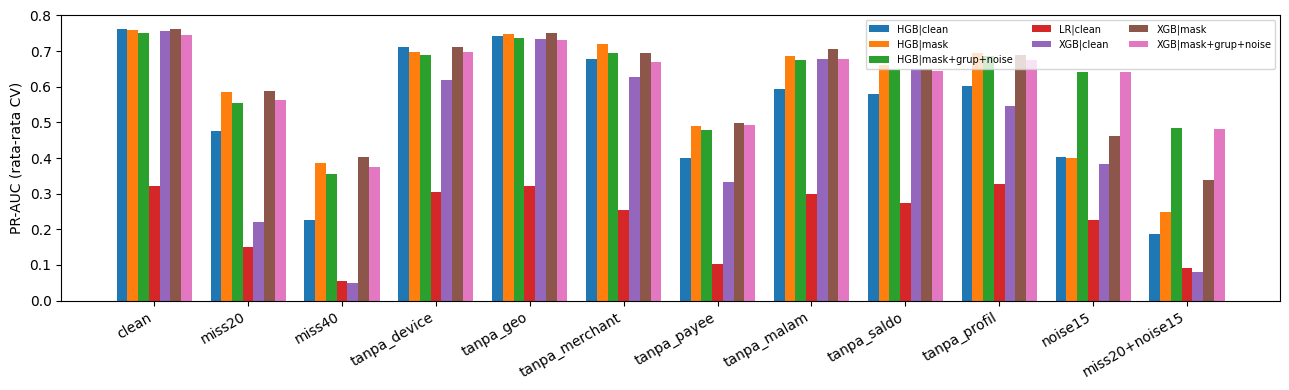

In [7]:
fig, ax = plt.subplots(figsize=(13, 4)); x = np.arange(len(SCEN)); cfgs = list(pr.index); wd = 0.8 / len(cfgs)
for i, c in enumerate(cfgs): ax.bar(x + i * wd, pr.loc[c, SCEN], wd, label=c)
ax.set_xticks(x + 0.4 - wd / 2); ax.set_xticklabels(SCEN, rotation=30, ha="right"); ax.set_ylabel("PR-AUC (rata-rata CV)"); ax.legend(fontsize=7, ncol=3); plt.tight_layout(); plt.show()

## 6. Apakah augmentasi merugikan data bersih?
Ini trade-off utamanya: terlalu banyak data rusak bisa menurunkan akurasi pada kondisi normal. Tabel berikut membandingkan PR-AUC **bersih** tiap resep terhadap `clean` (pasangan per fold; positif = lebih baik).

In [8]:
cl = res[res.scenario == "clean"].pivot_table(index="fold", columns="config", values="PR_AUC")
rows = []
for m in ("XGB", "HGB"):
    for v in VARIANTS[1:]:
        d = cl[f"{m}|{v}"] - cl[f"{m}|clean"]
        rows.append(dict(model=m, resep=v, PR_bersih_baseline=cl[f"{m}|clean"].mean(), PR_bersih_resep=cl[f"{m}|{v}"].mean(), selisih=d.mean(), fold_membaik=f"{int((d > 0).sum())}/{len(d)}", selisih_terburuk=d.min()))
clean_cost = pd.DataFrame(rows).set_index(["model", "resep"]).round(4); clean_cost

PR_bersih_baseline  PR_bersih_resep  selisih  \
model resep                                                           
XGB   mask                         0.7563           0.7618   0.0054   
      mask+grup+noise              0.7563           0.7459  -0.0104   
HGB   mask                         0.7625           0.7593  -0.0032   
      mask+grup+noise              0.7625           0.7514  -0.0111   

                      fold_membaik  selisih_terburuk  
model resep                                           
XGB   mask                     3/5           -0.0111  
      mask+grup+noise          1/5           -0.0247  
HGB   mask                     3/5           -0.0363  
      mask+grup+noise          1/5           -0.0458

## 7. Aturan pemilihan (ditetapkan sebelum melihat hasil)
* **Skor robust** per konfigurasi = 0,5 x PR-AUC bersih + 0,5 x rata-rata PR-AUC seluruh skenario kerusakan. Setengah bobot untuk akurasi normal, setengah untuk ketahanan.
* **Resep terbaik per model**: skor robust tertinggi, *dengan syarat* PR-AUC bersih tidak turun lebih dari **0,02** dari resep `clean` model itu (batas biaya akurasi yang kita terima).
* **Juara**: skor robust tertinggi di antara resep terpilih. Bila beberapa model berada dalam **1 standard error** (antar-fold) dari yang tertinggi, pilih yang paling sederhana (LR < HGB < XGB).
* **Challenger**: terbaik berikutnya dari keluarga model lain.

In [9]:
STRESS = [s for s in SCEN if s != "clean"]
fold_score = res.assign(kind=np.where(res.scenario == "clean", "clean", "stress")).groupby(["config", "fold", "kind"]).PR_AUC.mean().unstack("kind")
fold_score["robust"] = 0.5 * fold_score["clean"] + 0.5 * fold_score["stress"]
tab = fold_score.groupby("config").agg(clean=("clean", "mean"), stress=("stress", "mean"), robust=("robust", "mean"), robust_std=("robust", "std"))
tab["worst_retention"] = ret.min(axis=1); tab["se"] = tab.robust_std / np.sqrt(len(folds))

chosen = {}
for m in ("XGB", "HGB"):
    base = tab.loc[f"{m}|clean", "clean"]
    ok = [f"{m}|{v}" for v in VARIANTS if tab.loc[f"{m}|{v}", "clean"] >= base - 0.02]
    chosen[m] = max(ok, key=lambda c: tab.robust[c])
cand = {**chosen, "LR": "LR|clean"}
best_c = max(cand.values(), key=lambda c: tab.robust[c]); se = tab.se[best_c]
order = {"LR": 0, "HGB": 1, "XGB": 2}
near = [m for m, c in cand.items() if tab.robust[c] >= tab.robust[best_c] - se]
champion = min(near, key=lambda m: order[m]); challenger = max([m for m in cand if m != champion], key=lambda m: tab.robust[cand[m]])
print("resep terpilih per model:", chosen); print(f"skor robust tertinggi: {best_c} (SE {se:.4f}); dalam 1 SE: {near} -> JUARA = {champion}, CHALLENGER = {challenger}")
tab.round(4)

resep terpilih per model: {'XGB': 'XGB|mask', 'HGB': 'HGB|mask+grup+noise'}
skor robust tertinggi: HGB|mask+grup+noise (SE 0.0135); dalam 1 SE: ['XGB', 'HGB'] -> JUARA = HGB, CHALLENGER = XGB


,clean,stress,robust,robust_std,worst_retention,se
config,,,,,,
HGB|clean,0.7625,0.5092,0.6359,0.0411,0.2462,0.0184
HGB|mask,0.7593,0.5741,0.6667,0.0479,0.3272,0.0214
HGB|mask+grup+noise,0.7514,0.6040,0.6777,0.0303,0.4740,0.0135
LR|clean,0.3225,0.2187,0.2706,0.0541,0.1742,0.0242
XGB|clean,0.7563,0.4480,0.6022,0.0443,0.0666,0.0198
XGB|mask,0.7618,0.5905,0.6761,0.0490,0.4434,0.0219
XGB|mask+grup+noise,0.7459,0.6049,0.6754,0.0453,0.5025,0.0202


## 8. Evaluasi akhir konfigurasi terpilih
Model dilatih pada **seluruh pool**, lalu dievaluasi pada dua data yang tidak dipakai memilih resep:
* **Uji maju** (train Okt-Apr -> validasi Mei-Jun): mendeteksi sensitivitas terhadap waktu.
* **DEV-OOT** (Jul-Sep): bootstrap **per nasabah** (200 resampel) untuk interval kepercayaan, pada kondisi bersih *dan* 20% nilai hilang.

Resep pembanding `clean` (model notebook 02) ikut dievaluasi agar manfaat augmentasi terlihat langsung.

In [10]:
a_f, b_f = S.forward_split(pool); trf, vaf = pool.iloc[a_f], pool.iloc[b_f]
sc_f, sc_o = make_scenarios(vaf, seed=300), make_scenarios(oot, seed=400)
eval_cfgs = {"LR": ("LR", "clean")}                       # kunci = nama konfigurasi; baseline 'clean' selalu ikut sebagai pembanding
for m in ("XGB", "HGB"):
    eval_cfgs[f"{m}|clean"] = (m, "clean"); eval_cfgs[chosen[m]] = (m, chosen[m].split("|")[1])
fitted, fwd, oo, soot = {}, {}, {}, {}
for key, (m, v) in eval_cfgs.items():
    mf = build(m, v, trf); fwd[key] = {s: metrics(sc_f[s][L].values, mf.score(sc_f[s]), sc_f[s][W].values)["PR_AUC"] for s in ("clean", "miss20", "tanpa_payee")}
    fitted[key] = build(m, v, pool)
    soot[key] = {s: fitted[key].score(d) for s, d in sc_o.items()}
    oo[key] = {s: metrics(sc_o[s][L].values, soot[key][s], sc_o[s][W].values)["PR_AUC"] for s in ("clean", "miss20", "tanpa_payee", "noise15")}
    print(key, "selesai", flush=True)
final = pd.concat({"uji_maju": pd.DataFrame(fwd).T, "DEV-OOT": pd.DataFrame(oo).T}, axis=1).round(3); final

LR selesai


XGB|clean selesai


XGB|mask selesai


HGB|clean selesai


HGB|mask+grup+noise selesai


uji_maju                    DEV-OOT                     \
                       clean miss20 tanpa_payee   clean miss20 tanpa_payee   
LR                     0.280  0.119       0.095   0.209  0.099       0.073   
XGB|clean              0.709  0.169       0.279   0.699  0.127       0.298   
XGB|mask               0.726  0.568       0.529   0.654  0.506       0.399   
HGB|clean              0.720  0.468       0.399   0.661  0.409       0.345   
HGB|mask+grup+noise    0.748  0.531       0.512   0.622  0.498       0.381   

                             
                    noise15  
LR                    0.165  
XGB|clean             0.357  
XGB|mask              0.375  
HGB|clean             0.402  
HGB|mask+grup+noise   0.555

In [11]:
# Interval kepercayaan 95% (bootstrap per nasabah) pada DEV-OOT: kondisi bersih vs 20% hilang
codes, n_c = pd.factorize(oot.customer_id)[0], oot.customer_id.nunique(); rng = np.random.default_rng(SEED); keys = list(fitted); B = {(k, s): [] for k in keys for s in ("clean", "miss20")}
for _ in range(N_BOOT):
    wb = oot[W].values * np.bincount(rng.integers(0, n_c, n_c), minlength=n_c)[codes]
    for k in keys:
        for s in ("clean", "miss20"): B[(k, s)].append(average_precision_score(oot[L].values, soot[k][s], sample_weight=wb))
B = pd.DataFrame(B)
ci = pd.DataFrame({(s, q): B.xs(s, axis=1, level=1).quantile(p) for s in ("clean", "miss20") for q, p in (("PR_AUC", .5), ("CI_low", .025), ("CI_high", .975))}).round(3); display(ci)
a, b = chosen["XGB"], chosen["HGB"]
d = {s: (B[(a, s)] - B[(b, s)]).quantile([.025, .5, .975]).round(3).values for s in ("clean", "miss20")}
print(f"Selisih PR-AUC {a} - {b} [2.5%, median, 97.5%]:", d, "(CI melewati 0 = tidak beda nyata)")

clean                miss20               
                    PR_AUC CI_low CI_high PR_AUC CI_low CI_high
LR                   0.215  0.143   0.297  0.105  0.061   0.171
XGB|clean            0.706  0.619   0.798  0.133  0.074   0.217
XGB|mask             0.665  0.557   0.777  0.512  0.415   0.602
HGB|clean            0.671  0.567   0.768  0.417  0.348   0.470
HGB|mask+grup+noise  0.635  0.519   0.734  0.502  0.434   0.581

Selisih PR-AUC XGB|mask - HGB|mask+grup+noise [2.5%, median, 97.5%]: {'clean': array([-0.01 ,  0.033,  0.068]), 'miss20': array([-0.043,  0.01 ,  0.057])} (CI melewati 0 = tidak beda nyata)


In [12]:
# Stabilitas antar random seed (seed model DAN seed augmentasi berubah)
seed_rows = {}
for m, key in chosen.items():
    v = key.split("|")[1]; vals = []
    for sd in (1, 2, 3):
        mm = build(m, v, pool, seed=sd); vals.append([average_precision_score(sc_o[s][L], mm.score(sc_o[s]), sample_weight=sc_o[s][W]) for s in ("clean", "miss20")])
    seed_rows[key] = dict(clean=f"{np.mean([x[0] for x in vals]):.3f} ± {np.std([x[0] for x in vals]):.3f}", miss20=f"{np.mean([x[1] for x in vals]):.3f} ± {np.std([x[1] for x in vals]):.3f}")
pd.DataFrame(seed_rows).T

,clean,miss20
XGB|mask,0.669 ± 0.015,0.532 ± 0.017
HGB|mask+grup+noise,0.612 ± 0.047,0.391 ± 0.138


## 9. Membekukan model
Yang disimpan: model terpilih (dilatih pada pool), parameter dan resep, daftar fitur, serta ambang pita risiko.
Ambang dihitung dari skor DEV-OOT **bersih**: *suspicious* = presisi >= 5% (step-up / review), *high-risk* = presisi >= 50% (hold). Probabilitas dikoreksi prior karena negatif di-down-sample 3%.

In [13]:
def calibrate(p, k=S.NEG_KEEP): return p * k / (p * k + (1 - p))
def bands(y, s, w, prec_sus=0.05, prec_high=0.5):
    p_, r_, th = precision_recall_curve(y, s, sample_weight=w); first = lambda t: th[np.argmax(p_[:-1] >= t)] if (p_[:-1] >= t).any() else th[-1]
    return float(min(first(prec_sus), first(prec_high))), float(first(prec_high))
os.makedirs("models", exist_ok=True); frozen = {}
for k in fitted: joblib.dump(fitted[k], f"models/baseline_{k.replace('|', '_')}.joblib")   # semua konfigurasi yang dievaluasi, termasuk tanpa augmentasi (model notebook 02)
def key_of(m): return "LR" if m == "LR" else chosen[m]
for role, m in (("champion", champion), ("challenger", challenger)):
    k = key_of(m); t_s, t_h = bands(oot[L].values, calibrate(soot[k]["clean"]), oot[W].values)
    joblib.dump(fitted[k], f"models/robust_{role}.joblib")
    frozen[role] = dict(model=m, config=k, params=DEFAULTS[m], train_recipe=k.split("|")[1] if "|" in k else "clean", thr_suspicious=t_s, thr_high_risk=t_h,
                        oot_pr_auc_clean=float(final.loc[k, ("DEV-OOT", "clean")]), oot_pr_auc_miss20=float(final.loc[k, ("DEV-OOT", "miss20")]))
json.dump(dict(frozen=frozen, features=FEATS, numeric=NUM, categorical=CAT, alert_rate=ALERT, neg_keep=S.NEG_KEEP, chosen_recipe=chosen,
               robust_table=tab.round(4).to_dict(), rule="skor robust = 0.5*clean + 0.5*mean(stres); biaya akurasi bersih <= 0.02; 1-SE -> paling sederhana"),
          open(f"{ART}/selection_robust.json", "w"), indent=1)
frozen

{'champion': {'model': 'HGB',
  'config': 'HGB|mask+grup+noise',
  'params': {'max_iter': 300,
   'learning_rate': 0.05,
   'max_leaf_nodes': 31,
   'min_samples_leaf': 20,
   'l2_regularization': 0.001,
   'max_features': 1.0},
  'train_recipe': 'mask+grup+noise',
  'thr_suspicious': 0.0017654359750748604,
  'thr_high_risk': 0.1456198574196475,
  'oot_pr_auc_clean': 0.622,
  'oot_pr_auc_miss20': 0.498},
 'challenger': {'model': 'XGB',
  'config': 'XGB|mask',
  'params': {'n_estimators': 300,
   'learning_rate': 0.05,
   'max_depth': 5,
   'subsample': 0.8,
   'colsample_bytree': 0.8,
   'min_child_weight': 5.0,
   'reg_lambda': 1.0,
   'gamma': 0.0},
  'train_recipe': 'mask',
  'thr_suspicious': 0.002535842126235366,
  'thr_high_risk': 0.05366142466664314,
  'oot_pr_auc_clean': 0.654,
  'oot_pr_auc_miss20': 0.506}}

## 10. Ringkasan & implikasi untuk deployment
Ringkasan angka ada pada tabel bagian 5-8 dan `artifacts/selection_robust.json`. Hal yang perlu dibawa ke tahap deployment:

1. **Kontrak API harus mengizinkan fitur kosong** (`null`), bukan menolak request. Model ini dilatih untuk itu.
2. **Pantau tingkat kekosongan fitur** per grup di produksi. Bila tingkat kekosongan sebuah grup melonjak jauh di atas yang disimulasikan di sini (20-40% sel, atau satu grup penuh), skor perlu diberi tanda 'kualitas rendah' dan keputusan jatuh ke aturan deterministik §6.3.
3. Fitur **payee** tetap paling berpengaruh: sumber datanya perlu SLA tertinggi.
4. Data TEST belum disentuh; langkah berikutnya `03_final_test.ipynb` untuk model beku di atas.